
# Department-Level Solar Potential Assessment Using PVGIS

## Objective

Estimate the theoretical photovoltaic energy yield for the six departments included in this study: 04, 05, 07, 26, 38, and 84.

## Methodology

- Query the PVGIS API for each selected geographical location.
- Apply consistent photovoltaic system parameters to ensure comparability across departments.
- Validate the retrieved values and document the assumptions used.
- Export the results for comparison with the installed capacity and empirical energy yield data.

## Limitations

Results obtained from a single geographical point per department provide an initial approximation. They do not represent an area-weighted departmental average and do not account for all local variations in terrain, solar orientation, or operating conditions.


## 1. Configuration and Geographic Reference Points

The six departmental prefectures are used as representative locations for the initial PVGIS assessment. These points provide a consistent starting point for comparing photovoltaic yields under identical system assumptions.

**Limitation:** prefecture-based estimates do not represent department-wide averages. Local elevation, terrain, and solar irradiation may vary considerably within each department.

In [1]:

import pandas as pd
import requests
import time

# Department prefectures used as representative locations.
# Coordinates are approximate WGS84 latitude/longitude.

points = pd.DataFrame([
    {
        "codeDepartement": "04",
        "departement": "Alpes-de-Haute-Provence",
        "ville_reference": "Digne-les-Bains",
        "latitude": 44.0935,
        "longitude": 6.2353
    },
    {
        "codeDepartement": "05",
        "departement": "Hautes-Alpes",
        "ville_reference": "Gap",
        "latitude": 44.5594,
        "longitude": 6.0794
    },
    {
        "codeDepartement": "07",
        "departement": "Ardeche",
        "ville_reference": "Privas",
        "latitude": 44.7352,
        "longitude": 4.5991
    },
    {
        "codeDepartement": "26",
        "departement": "Drome",
        "ville_reference": "Valence",
        "latitude": 44.9333,
        "longitude": 4.8921
    },
    {
        "codeDepartement": "38",
        "departement": "Isere",
        "ville_reference": "Grenoble",
        "latitude": 45.1864,
        "longitude": 5.7364
    },
    {
        "codeDepartement": "84",
        "departement": "Vaucluse",
        "ville_reference": "Avignon",
        "latitude": 43.9493,
        "longitude": 4.8055
    }
])

# Basic validation
assert points["codeDepartement"].is_unique
assert len(points) == 6
assert points[["latitude", "longitude"]].notna().all().all()

display(points)


,codeDepartement,departement,ville_reference,latitude,longitude
0,04,Alpes-de-Haute-Provence,Digne-les-Bains,44.0935,6.2353
1,05,Hautes-Alpes,Gap,44.5594,6.0794
2,07,Ardeche,Privas,44.7352,4.5991
3,26,Drome,Valence,44.9333,4.8921
4,38,Isere,Grenoble,45.1864,5.7364
5,84,Vaucluse,Avignon,43.9493,4.8055



## 2. PVGIS API Queries

Retrieve the estimated annual photovoltaic energy yield for each reference location using the European Commission's PVGIS service. The same system configuration is applied to all six locations to ensure comparability.

The initial assessment assumes a 1 kWp crystalline-silicon system, fixed mounting, a 35° tilt angle, a south-facing orientation, and 14% system losses.


In [2]:

# PVGIS API configuration
PVGIS_URL = "https://re.jrc.ec.europa.eu/api/v5_3/PVcalc"

SYSTEM_PARAMS = {
    "peakpower": 1,          # kWp
    "pvtechchoice": "crystSi",
    "mountingplace": "free",
    "loss": 14,              # %
    "angle": 35,              # degrees
    "aspect": 0,              # 0 = south
    "outputformat": "json"
}

results = []
errors = []

for _, point in points.iterrows():
    params = {
        **SYSTEM_PARAMS,
        "lat": float(point["latitude"]),
        "lon": float(point["longitude"])
    }

    try:
        response = requests.get(
            PVGIS_URL,
            params=params,
            timeout=60
        )
        response.raise_for_status()
        data = response.json()

        annual = data["outputs"]["totals"]["fixed"]

        results.append({
            "codeDepartement": point["codeDepartement"],
            "departement": point["departement"],
            "ville_reference": point["ville_reference"],
            "latitude": point["latitude"],
            "longitude": point["longitude"],
            "inclinaison_deg": SYSTEM_PARAMS["angle"],
            "orientation_deg": SYSTEM_PARAMS["aspect"],
            "pertes_pct": SYSTEM_PARAMS["loss"],
            "productible_PVGIS_kWh_kWc": annual["E_y"],
            "irradiation_plan_kWh_m2": annual["H(i)_y"]
        })

    except (requests.RequestException, KeyError, ValueError) as exc:
        errors.append({
            "codeDepartement": point["codeDepartement"],
            "ville_reference": point["ville_reference"],
            "erreur": str(exc)
        })

    time.sleep(1)

pvgis = pd.DataFrame(results)

print(f"Successful requests: {len(pvgis)}/6")
print(f"Failed requests: {len(errors)}")

if not pvgis.empty:
    display(
        pvgis[
            [
                "codeDepartement",
                "ville_reference",
                "productible_PVGIS_kWh_kWc",
                "irradiation_plan_kWh_m2"
            ]
        ].round(1)
    )

if errors:
    display(pd.DataFrame(errors))


Successful requests: 6/6
Failed requests: 0


,codeDepartement,ville_reference,productible_PVGIS_kWh_kWc,irradiation_plan_kWh_m2
0,04,Digne-les-Bains,1508.5,1899.2
1,05,Gap,1536.4,1941.9
2,07,Privas,1396.9,1754.1
3,26,Valence,1391.7,1760.0
4,38,Grenoble,1362.1,1713.4
5,84,Avignon,1560.3,1979.2


## 3. Export and Data Validation

Validate the PVGIS results and export them to a CSV file for comparison with the empirical departmental indicators.

The output contains estimated annual photovoltaic energy yield and annual irradiation for each reference location. These estimates are based on a standardized system configuration and are intended for comparison across departments.

In [3]:
from pathlib import Path

# Check that all six departments have a successful result
assert len(pvgis) == 6, "Expected one successful result per department."
assert pvgis["codeDepartement"].is_unique
assert pvgis["productible_PVGIS_kWh_kWc"].notna().all()
assert pvgis["irradiation_plan_kWh_m2"].notna().all()

# Create the output directory
output_dir = Path("dataset/data clean")
output_dir.mkdir(parents=True, exist_ok=True)

# Export the PVGIS results
output_path = output_dir / "potentiel_solaire_PVGIS.csv"

pvgis.to_csv(
    output_path,
    sep=";",
    decimal=".",
    index=False,
    encoding="utf-8"
)

print(f"File exported to: {output_path}")
display(pvgis.round(2))

File exported to: dataset\data clean\potentiel_solaire_PVGIS.csv


,codeDepartement,departement,ville_reference,latitude,longitude,inclinaison_deg,orientation_deg,pertes_pct,productible_PVGIS_kWh_kWc,irradiation_plan_kWh_m2
0,04,Alpes-de-Haute-Provence,Digne-les-Bains,44.09,6.24,35,0,14,1508.49,1899.17
1,05,Hautes-Alpes,Gap,44.56,6.08,35,0,14,1536.45,1941.90
2,07,Ardeche,Privas,44.74,4.60,35,0,14,1396.91,1754.10
3,26,Drome,Valence,44.93,4.89,35,0,14,1391.71,1760.00
4,38,Isere,Grenoble,45.19,5.74,35,0,14,1362.07,1713.36
5,84,Vaucluse,Avignon,43.95,4.81,35,0,14,1560.26,1979.23


## 4. Comparison with Empirical Departmental Data

Merge the PVGIS estimates with the cleaned departmental summary using department codes as the common key.

This comparison helps assess the differences between theoretical photovoltaic yield at each reference location and the empirical yield derived from the observed installation data.

In [4]:
from pathlib import Path
import pandas as pd

data_dir = Path("dataset/data clean")

# Load the departmental summary
synthese = pd.read_csv(
    data_dir / "synthese_dep_edition.csv",
    sep=";",
    encoding="utf-8",
    dtype={"codeDepartement": str}
)

# Standardize department codes before merging
synthese["codeDepartement"] = (
    synthese["codeDepartement"].astype(str).str.zfill(2)
)
pvgis["codeDepartement"] = (
    pvgis["codeDepartement"].astype(str).str.zfill(2)
)

# Merge the two datasets
comparaison = synthese.merge(
    pvgis[
        [
            "codeDepartement",
            "productible_PVGIS_kWh_kWc",
            "irradiation_plan_kWh_m2"
        ]
    ],
    on="codeDepartement",
    how="left",
    validate="many_to_one"
)

display(comparaison.head())

,codeDepartement,edition,centrales,puissance_MW,injectee_GWh,part_prod_renseignee,rend_ref_kwh_kw,productible_GWh,departement,superficie_km2,puissance_MW_km2,productible_GWh_km2,productible_PVGIS_kWh_kWc,irradiation_plan_kWh_m2
0,04,2017,258,288.969,393.932,1.000,1492.0,431.141748,Alpes-de-Haute-Provence,6925,0.041728,0.062259,1508.49,1899.17
1,04,2018,272,289.045,426.951,0.996,1492.0,431.255140,Alpes-de-Haute-Provence,6925,0.041739,0.062275,1508.49,1899.17
2,04,2019,293,295.993,478.490,1.000,1492.0,441.621556,Alpes-de-Haute-Provence,6925,0.042743,0.063772,1508.49,1899.17
3,04,2020,331,327.912,475.911,0.982,1492.0,489.244704,Alpes-de-Haute-Provence,6925,0.047352,0.070649,1508.49,1899.17
4,04,2021,395,354.653,519.491,0.970,1492.0,529.142276,Alpes-de-Haute-Provence,6925,0.051213,0.076410,1508.49,1899.17


In [5]:
# One row per department for the theoretical PVGIS comparison
comparaison_dep = (
    comparaison[
        [
            "codeDepartement",
            "departement",
            "superficie_km2",
            "rend_ref_kwh_kw",
            "productible_PVGIS_kWh_kWc",
            "irradiation_plan_kWh_m2"
        ]
    ]
    .drop_duplicates(subset="codeDepartement")
    .sort_values("codeDepartement")
    .reset_index(drop=True)
)

display(comparaison_dep.round(2))

,codeDepartement,departement,superficie_km2,rend_ref_kwh_kw,productible_PVGIS_kWh_kWc,irradiation_plan_kWh_m2
0,04,Alpes-de-Haute-Provence,6925,1492.0,1508.49,1899.17
1,05,Hautes-Alpes,5549,1410.0,1536.45,1941.90
2,07,Ardèche,5529,1292.0,1396.91,1754.10
3,26,Drôme,6530,1278.0,1391.71,1760.00
4,38,Isère,7431,1184.0,1362.07,1713.36
5,84,Vaucluse,3567,1342.0,1560.26,1979.23


In [6]:
# Calculate absolute and relative differences
comparaison_dep["ecart_kWh_kWc"] = (
    comparaison_dep["productible_PVGIS_kWh_kWc"]
    - comparaison_dep["rend_ref_kwh_kw"]
)

comparaison_dep["ecart_pct"] = (
    comparaison_dep["ecart_kWh_kWc"]
    / comparaison_dep["rend_ref_kwh_kw"]
    * 100
)

display(
    comparaison_dep[
        [
            "codeDepartement",
            "departement",
            "rend_ref_kwh_kw",
            "productible_PVGIS_kWh_kWc",
            "ecart_kWh_kWc",
            "ecart_pct"
        ]
    ].round(2)
)

,codeDepartement,departement,rend_ref_kwh_kw,productible_PVGIS_kWh_kWc,ecart_kWh_kWc,ecart_pct
0,04,Alpes-de-Haute-Provence,1492.0,1508.49,16.49,1.11
1,05,Hautes-Alpes,1410.0,1536.45,126.45,8.97
2,07,Ardèche,1292.0,1396.91,104.91,8.12
3,26,Drôme,1278.0,1391.71,113.71,8.90
4,38,Isère,1184.0,1362.07,178.07,15.04
5,84,Vaucluse,1342.0,1560.26,218.26,16.26


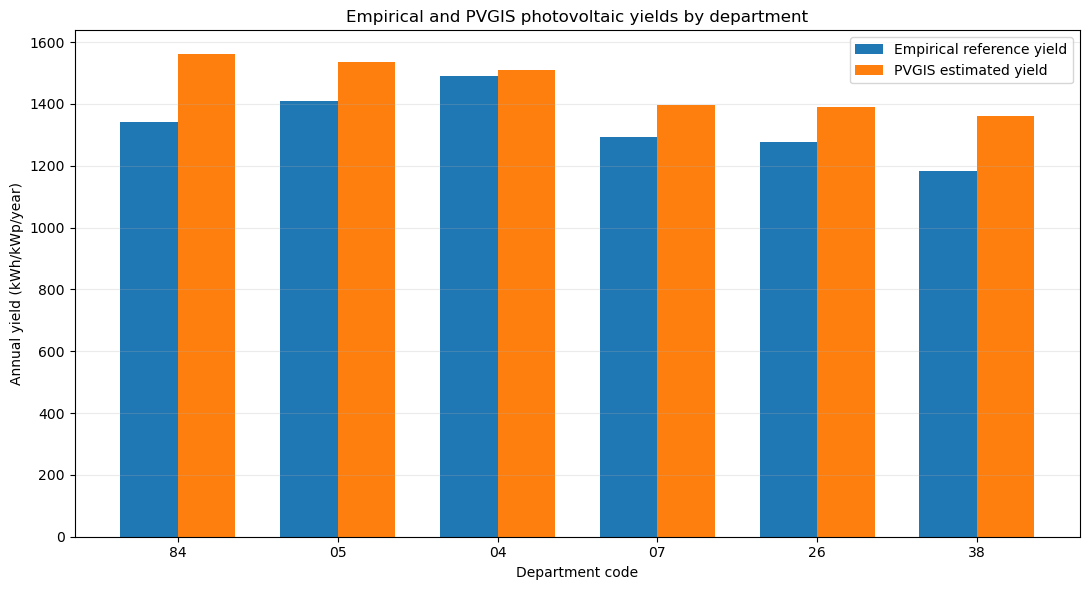

In [7]:
import matplotlib.pyplot as plt
import numpy as np

df_plot = comparaison_dep.sort_values(
    "productible_PVGIS_kWh_kWc",
    ascending=False
)

x = np.arange(len(df_plot))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    df_plot["rend_ref_kwh_kw"],
    width,
    label="Empirical reference yield"
)

ax.bar(
    x + width / 2,
    df_plot["productible_PVGIS_kWh_kWc"],
    width,
    label="PVGIS estimated yield"
)

ax.set_xticks(x)
ax.set_xticklabels(df_plot["codeDepartement"])
ax.set_xlabel("Department code")
ax.set_ylabel("Annual yield (kWh/kWp/year)")
ax.set_title("Empirical and PVGIS photovoltaic yields by department")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 5. Comparison and Interpretation

PVGIS estimates a higher annual photovoltaic yield than the empirical reference yield in all six departments. The relative differences range from 1.11% in Alpes-de-Haute-Provence to 16.26% in Vaucluse. Isère also shows a relatively large difference of 15.04%.

These differences should not be interpreted directly as measures of system underperformance. PVGIS estimates are based on a representative geographical point and a standardized photovoltaic system configuration, whereas empirical reference yields are derived from observed installation data.

The comparison therefore provides an initial assessment of the consistency between theoretical estimates and empirical reference values. Further analysis would be required to distinguish the effects of geographical representativeness, weather conditions, installation characteristics, and operating constraints.

Each department is represented by a single reference location. The PVGIS estimates should therefore be interpreted as location-specific results rather than department-wide averages. A more comprehensive assessment would require multiple locations or an area-weighted analysis for each department.

In [8]:
from pathlib import Path

output_path = Path("dataset/data clean/comparaison_PVGIS_empirique.csv")

comparaison_dep.to_csv(
    output_path,
    sep=";",
    decimal=".",
    index=False,
    encoding="utf-8"
)

print(f"Comparative dataset exported to: {output_path}")

Comparative dataset exported to: dataset\data clean\comparaison_PVGIS_empirique.csv
